
**Pergunta central:** como preparar e reduzir a base preservando a informação relevante?

Dataset: 9 tabelas do [Olist Brazilian E-Commerce](https://www.kaggle.com/data/raw/olistbr/brazilian-ecommerce), em `data/raw/`. Para baixar: `uv run --with kagglehub python scripts/download_dataset.py`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42  # semente: garante que os resultados sejam sempre iguais
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "raw"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
arquivos = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geo": "olist_geolocation_dataset.csv",
    "cat_tr": "product_category_name_translation.csv",
}

dados = {}

for nome, arq in arquivos.items():
    dados[nome] = pd.read_csv(DATA_DIR / arq)
    print(f"{nome:10s} {dados[nome].shape[0]:>10,} linhas x {dados[nome].shape[1]} colunas")

orders         99,441 linhas x 8 colunas


customers      99,441 linhas x 5 colunas


items         112,650 linhas x 7 colunas


reviews        99,224 linhas x 7 colunas
payments      103,886 linhas x 5 colunas
products       32,951 linhas x 9 colunas
sellers         3,095 linhas x 4 colunas


geo         1,000,163 linhas x 5 colunas
cat_tr             71 linhas x 2 colunas



Antes de qualquer transformação, vamos investigar cada tabela: tipos, valores ausentes, duplicatas e valores incoerentes. Toda transformação posterior deve responder: **"que problema nos dados justifica isso?"**

In [3]:
for nome in ["orders", "items", "reviews", "payments", "products", "customers"]:
    print(f"\n=== {nome} ===")
    print(dados[nome].dtypes.to_string())


=== orders ===
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object

=== items ===
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64

=== reviews ===
review_id                  object
order_id                   object
review_score                int64
review_comment_title       object
review_comment_message     object
review_creation_date       object
review_answer_timestamp    object

=== payments ===
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64

In [4]:
ausentes = {}
for nome, df in dados.items():
    n = df.isna().sum()
    n = n[n > 0]
    if len(n):
        ausentes[nome] = pd.DataFrame({"ausentes": n, "pct": (n / len(df) * 100).round(2)})

for nome, tab in ausentes.items():
    print(f"\n=== {nome} ===")
    print(tab.to_string())


=== orders ===
                               ausentes   pct
order_approved_at                   160  0.16
order_delivered_carrier_date       1783  1.79
order_delivered_customer_date      2965  2.98

=== reviews ===
                        ausentes    pct
review_comment_title       87656  88.34
review_comment_message     58247  58.70

=== products ===
                            ausentes   pct
product_category_name            610  1.85
product_name_lenght              610  1.85
product_description_lenght       610  1.85
product_photos_qty               610  1.85
product_weight_g                   2  0.01
product_length_cm                  2  0.01
product_height_cm                  2  0.01
product_width_cm                   2  0.01


In [5]:
chaves = {
    "orders": ["order_id"],
    "customers": ["customer_id"],
    "reviews": ["review_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
}
for nome, chave in chaves.items():
    df = dados[nome]
    print(f"{nome:10s} linhas inteiras duplicadas: {df.duplicated().sum():>7,} | "
          f"chave {chave} duplicada: {df.duplicated(subset=chave).sum():>7,}")

print("\nreviews: pedidos com mais de 1 avaliação:",
      (dados["reviews"]["order_id"].value_counts() > 1).sum())
print("geo: linhas duplicadas:", dados["geo"].duplicated().sum())

orders     linhas inteiras duplicadas:       0 | chave ['order_id'] duplicada:       0
customers  linhas inteiras duplicadas:       0 | chave ['customer_id'] duplicada:       0


reviews    linhas inteiras duplicadas:       0 | chave ['review_id'] duplicada:     814
products   linhas inteiras duplicadas:       0 | chave ['product_id'] duplicada:       0
sellers    linhas inteiras duplicadas:       0 | chave ['seller_id'] duplicada:       0

reviews: pedidos com mais de 1 avaliação: 547


geo: linhas duplicadas: 261831



Ausente não significa erro. Antes de preencher, verificamos **por que** falta.

In [6]:
orders = dados["orders"]

print(orders["order_status"].value_counts().to_string())

sem_entrega = orders["order_delivered_customer_date"].isna()
print("\nPedidos sem data de entrega, por status:")
print(orders.loc[sem_entrega, "order_status"].value_counts().to_string())

print(f"\nPedidos 'delivered' que mesmo assim estão sem data de entrega:",
      (sem_entrega & (orders["order_status"] == "delivered")).sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Pedidos sem data de entrega, por status:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2

Pedidos 'delivered' que mesmo assim estão sem data de entrega: 8


In [7]:
products = dados["products"]
cols_meta = ["product_category_name", "product_name_lenght",
             "product_description_lenght", "product_photos_qty"]

mesmas_linhas = products[cols_meta].isna().all(axis=1).sum()
print("Produtos com as 4 colunas de metadado ausentes ao mesmo tempo:", mesmas_linhas)

cat = dados["cat_tr"]
sem_traducao = set(products["product_category_name"].dropna()) - set(cat["product_category_name"])
print("Categorias sem tradução em inglês:", sem_traducao)

Produtos com as 4 colunas de metadado ausentes ao mesmo tempo: 610
Categorias sem tradução em inglês: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


In [8]:
reviews = dados["reviews"]
repetidos = reviews.loc[reviews.duplicated("order_id", keep=False)].sort_values(["order_id", "review_creation_date"])

print("Linhas de reviews envolvidas:", len(repetidos))
print("Notas diferentes dentro do mesmo pedido:",
      (repetidos.groupby("order_id")["review_score"].nunique() > 1).sum(), "pedidos")
repetidos[["order_id", "review_id", "review_score", "review_creation_date"]].head(6)

Linhas de reviews envolvidas: 1098
Notas diferentes dentro do mesmo pedido: 202 pedidos


,order_id,review_id,review_score,review_creation_date
22423,0035246a40f520710769010f752e7507,2a74b0559eb58fc1ff842ecc999594cb,5,2017-08-25 00:00:00
25612,0035246a40f520710769010f752e7507,89a02c45c340aeeb1354a24e7d4b2c1e,5,2017-08-29 00:00:00
22779,013056cfe49763c6f66bda03396c5ee3,ab30810c29da5da8045216f0f62652a2,5,2018-02-22 00:00:00
68633,013056cfe49763c6f66bda03396c5ee3,73413b847f63e02bc752b364f6d05ee9,4,2018-03-04 00:00:00
854,0176a6846bcb3b0d3aa3116a9a768597,830636803620cdf8b6ffaf1b2f6e92b2,5,2017-12-30 00:00:00
83224,0176a6846bcb3b0d3aa3116a9a768597,d8e8c42271c8fb67b9dad95d98c8ff80,5,2017-12-30 00:00:00


In [9]:
reviews = dados["reviews"].copy()
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

ordenado = reviews.sort_values(["order_id", "review_creation_date", "review_answer_timestamp"])
mais_antiga = ordenado.drop_duplicates("order_id", keep="first").set_index("order_id")["review_score"]
mais_recente = ordenado.drop_duplicates("order_id", keep="last").set_index("order_id")["review_score"]

comparacao = pd.DataFrame({"antiga": mais_antiga, "recente": mais_recente})
print("Pedidos em que a nota muda conforme a regra:", (comparacao["antiga"] != comparacao["recente"]).sum())

muda_classe = ((comparacao["antiga"] <= 2) != (comparacao["recente"] <= 2)).sum()
print("Pedidos em que a classe satisfeito/insatisfeito muda:", muda_classe,
      f"({muda_classe / len(comparacao):.3%} do total)")

Pedidos em que a nota muda conforme a regra: 202
Pedidos em que a classe satisfeito/insatisfeito muda: 96 (0.097% do total)


In [10]:
for coluna in ["order_approved_at", "order_delivered_carrier_date"]:
    sem = orders[coluna].isna()
    print(f"\n{coluna}: {sem.sum()} ausentes")
    print(orders.loc[sem, "order_status"].value_counts().to_string())

cancelados_com_entrega = orders[(orders["order_status"] == "canceled")
                                & orders["order_delivered_customer_date"].notna()]
print("\nCancelados que têm data de entrega:", len(cancelados_com_entrega))


order_approved_at: 160 ausentes
order_status
canceled     141
delivered     14
created        5

order_delivered_carrier_date: 1783 ausentes
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2

Cancelados que têm data de entrega: 6



- Ausência de data em pedidos não finalizados é **esperada**: não se imputa.
- Pedidos `delivered` com datas ausentes (8 de entrega, 14 de aprovação, 2 de postagem) são inconsistências raras.
- Avaliação duplicada por pedido: ficamos com a **mais recente**. A escolha altera a classe de apenas 0,097% dos pedidos.

In [11]:
for nome, col in [("customers", "customer_zip_code_prefix"),
                  ("sellers", "seller_zip_code_prefix"),
                  ("geo", "geolocation_zip_code_prefix")]:
    print(f"{nome:10s} {col:30s} tipo: {dados[nome][col].dtype}")

zips_geo = set(dados["geo"]["geolocation_zip_code_prefix"])
for nome, col in [("customers", "customer_zip_code_prefix"), ("sellers", "seller_zip_code_prefix")]:
    sem_geo = (~dados[nome][col].isin(zips_geo)).sum()
    print(f"{nome}: linhas cujo CEP não existe em geo: {sem_geo} ({sem_geo / len(dados[nome]):.2%})")

customers  customer_zip_code_prefix       tipo: int64
sellers    seller_zip_code_prefix         tipo: int64
geo        geolocation_zip_code_prefix    tipo: int64
customers: linhas cujo CEP não existe em geo: 278 (0.28%)
sellers: linhas cujo CEP não existe em geo: 7 (0.23%)



Unidade de análise: **o pedido**. Primeiro, definimos quais pedidos entram (recorte), depois agregamos itens, pagamentos e geografia por pedido.

In [12]:
colunas_data = {
    "orders": ["order_purchase_timestamp", "order_approved_at",
               "order_delivered_carrier_date", "order_delivered_customer_date",
               "order_estimated_delivery_date"],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
    "items": ["shipping_limit_date"],
}

for tabela, colunas in colunas_data.items():
    for coluna in colunas:
        dados[tabela][coluna] = pd.to_datetime(dados[tabela][coluna])

dados["orders"].dtypes.to_string()

'order_id                                 object\ncustomer_id                              object\norder_status                             object\norder_purchase_timestamp         datetime64[ns]\norder_approved_at                datetime64[ns]\norder_delivered_carrier_date     datetime64[ns]\norder_delivered_customer_date    datetime64[ns]\norder_estimated_delivery_date    datetime64[ns]'

In [13]:
orders = dados["orders"]

funil = {"todos os pedidos": len(orders)}

entregues = orders[orders["order_status"] == "delivered"]
funil["status = delivered"] = len(entregues)

com_data = entregues[entregues["order_delivered_customer_date"].notna()]
funil["... e com data de entrega"] = len(com_data)

review_final = (
    dados["reviews"]
    .sort_values(["order_id", "review_creation_date", "review_answer_timestamp"])
    .drop_duplicates("order_id", keep="last")      # a mais recente (decisão D2)
    .set_index("order_id")[["review_score"]]
)

base = com_data.set_index("order_id").join(review_final, how="inner")
funil["... e com avaliação"] = len(base)

for etapa, n in funil.items():
    print(f"{etapa:30s} {n:>8,}")

todos os pedidos                 99,441
status = delivered               96,478
... e com data de entrega        96,470
... e com avaliação              95,824


In [14]:
produtos = dados["products"].merge(dados["cat_tr"], on="product_category_name", how="left")

produtos["categoria"] = (
    produtos["product_category_name_english"]
    .fillna(produtos["product_category_name"])
    .fillna("sem_categoria")
)

print("Produtos com peso 0:", (produtos["product_weight_g"] == 0).sum())
produtos.loc[produtos["product_weight_g"] == 0, "product_weight_g"] = np.nan

print("Categorias distintas:", produtos["categoria"].nunique())
print("Produtos 'sem_categoria':", (produtos["categoria"] == "sem_categoria").sum())

Produtos com peso 0: 4
Categorias distintas: 74
Produtos 'sem_categoria': 610


In [15]:
itens = dados["items"].merge(
    produtos[["product_id", "categoria", "product_weight_g", "product_photos_qty"]],
    on="product_id", how="left",
)
itens = itens[itens["order_id"].isin(base.index)]   # só os pedidos do recorte

agg_itens = itens.groupby("order_id").agg(
    n_itens=("order_item_id", "count"),
    preco_total=("price", "sum"),
    frete_total=("freight_value", "sum"),
    peso_total_g=("product_weight_g", lambda s: s.sum(min_count=1)),
    n_fotos_medio=("product_photos_qty", "mean"),
)

item_principal = (
    itens.loc[itens.groupby("order_id")["price"].idxmax(), ["order_id", "categoria", "seller_id"]]
    .set_index("order_id")
    .rename(columns={"categoria": "categoria_principal", "seller_id": "vendedor_principal"})
)

print(agg_itens.shape, item_principal.shape)
agg_itens.describe().round(2)

(95824, 5) (95824, 2)


,n_itens,preco_total,frete_total,peso_total_g,n_fotos_medio
count,95824.00,95824.00,95824.00,95802.00,94500.00
mean,1.14,136.80,22.76,2382.97,2.25
std,0.53,207.79,21.52,4766.16,1.74
min,1.00,0.85,0.00,2.00,1.00
25%,1.00,45.90,13.84,300.00,1.00
50%,1.00,86.25,17.16,750.00,2.00
75%,1.00,149.90,23.99,2050.00,3.00
max,21.00,13440.00,1794.96,184400.00,20.00


In [16]:
pagamentos = dados["payments"]
pagamentos = pagamentos[pagamentos["order_id"].isin(base.index)]

n_parcelas = pagamentos.groupby("order_id")["payment_installments"].max().rename("n_parcelas")

pagamento_tipo = (
    pagamentos.sort_values("payment_value", ascending=False)
    .drop_duplicates("order_id")
    .set_index("order_id")["payment_type"]
    .rename("pagamento_tipo")
)

print("Pedidos com n_parcelas = 0:", (n_parcelas == 0).sum())
print(pagamento_tipo.value_counts().to_string())

Pedidos com n_parcelas = 0: 2
pagamento_tipo
credit_card    72331
boleto         19062
voucher         2953
debit_card      1477


In [17]:
base = (
    base.join(agg_itens, how="left")
        .join(item_principal, how="left")
        .join(n_parcelas, how="left")
        .join(pagamento_tipo, how="left")
)

print("Formato da base:", base.shape)
colunas_novas = ["n_itens", "preco_total", "frete_total", "peso_total_g", "n_fotos_medio",
                 "categoria_principal", "n_parcelas", "pagamento_tipo"]
base[colunas_novas].isna().sum()

Formato da base: (95824, 17)


n_itens                   0
preco_total               0
frete_total               0
peso_total_g             22
n_fotos_medio          1324
categoria_principal       0
n_parcelas                1
pagamento_tipo            1
dtype: int64

In [18]:
geo = dados["geo"].drop_duplicates()
print("geo: linhas únicas:", f"{len(geo):,}")

dentro_brasil = (geo["geolocation_lat"].between(-33.75, 5.27)
                 & geo["geolocation_lng"].between(-73.99, -34.79))
print("Coordenadas fora do retângulo do Brasil:", (~dentro_brasil).sum())
geo = geo[dentro_brasil]

centroides = geo.groupby("geolocation_zip_code_prefix").agg(
    lat=("geolocation_lat", "median"),
    lng=("geolocation_lng", "median"),
)
print("CEPs com coordenada:", len(centroides))

geo: linhas únicas: 738,332
Coordenadas fora do retângulo do Brasil: 33
CEPs com coordenada: 19010


In [19]:
clientes = dados["customers"].set_index("customer_id")[
    ["customer_unique_id", "customer_zip_code_prefix", "customer_state"]]
vendedores = dados["sellers"].set_index("seller_id")[
    ["seller_zip_code_prefix", "seller_state"]]

base = (
    base.join(clientes, on="customer_id")
        .join(vendedores, on="vendedor_principal")
        .join(centroides.add_suffix("_cli"), on="customer_zip_code_prefix")
        .join(centroides.add_suffix("_vend"), on="seller_zip_code_prefix")
)

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

base["distancia_km"] = haversine_km(base["lat_cli"], base["lng_cli"],
                                    base["lat_vend"], base["lng_vend"])
base = base.drop(columns=["lat_cli", "lng_cli", "lat_vend", "lng_vend"])

In [20]:
d = base["distancia_km"]
print("Distância: ausentes =", d.isna().sum(), "| zeros =", (d == 0).sum(),
      "| > 4400 km =", (d > 4400).sum(), "| máximo =", round(d.max(), 1))
d.describe().round(1)

Distância: ausentes = 476 | zeros = 22 | > 4400 km = 0 | máximo = 3398.5


count    95348.0
mean       600.1
std        592.0
min          0.0
25%        185.0
50%        433.8
75%        798.2
max       3398.5
Name: distancia_km, dtype: float64

In [21]:
dias = lambda fim, ini: (base[fim] - base[ini]).dt.total_seconds() / 86400

base["atraso_dias"]   = dias("order_delivered_customer_date", "order_estimated_delivery_date")  # >0 = atrasou
base["entrega_dias"]  = dias("order_delivered_customer_date", "order_purchase_timestamp")
base["manuseio_dias"] = dias("order_delivered_carrier_date",  "order_purchase_timestamp")
base["aprovacao_h"]   = (base["order_approved_at"] - base["order_purchase_timestamp"]).dt.total_seconds() / 3600

base["hora_compra"]       = base["order_purchase_timestamp"].dt.hour
base["dia_semana_compra"] = base["order_purchase_timestamp"].dt.day_name()
base["mes_compra"]        = base["order_purchase_timestamp"].dt.month  # 1-12

In [22]:
base["valor_pedido"]         = base["preco_total"] + base["frete_total"]
base["frete_ratio"]          = base["frete_total"] / base["valor_pedido"]
base["preco_unitario_medio"] = base["preco_total"] / base["n_itens"]

base["insatisfeito"] = (base["review_score"] <= 2).astype(int)
print(f"Taxa de insatisfação: {base['insatisfeito'].mean():.1%}")

Taxa de insatisfação: 12.8%


In [23]:
numericas = ["atraso_dias", "entrega_dias", "manuseio_dias", "aprovacao_h", "frete_total", "preco_total",
             "valor_pedido", "frete_ratio", "n_itens", "preco_unitario_medio", "distancia_km",
             "n_parcelas", "peso_total_g", "n_fotos_medio", "hora_compra"]

print("Formato:", base.shape)
print("Manuseio negativo (X1):", (base["manuseio_dias"] < 0).sum())
print("Aprovação negativa:", (base["aprovacao_h"] < 0).sum())
print("Entrega <= 0:", (base["entrega_dias"] <= 0).sum())
base[numericas].describe().T.round(2)

Formato: (95824, 34)
Manuseio negativo (X1): 164
Aprovação negativa: 0
Entrega <= 0: 0


,count,mean,std,min,25%,50%,75%,max
atraso_dias,95824.0,-11.22,10.11,-146.02,-16.25,-11.97,-6.41,188.98
entrega_dias,95824.0,12.52,9.46,0.53,6.76,10.21,15.66,208.35
manuseio_dias,95823.0,3.22,3.58,-171.21,1.13,2.20,4.06,125.78
aprovacao_h,95810.0,10.28,20.54,0.00,0.22,0.34,14.52,741.44
frete_total,95824.0,22.76,21.52,0.00,13.84,17.16,23.99,1794.96
preco_total,95824.0,136.80,207.79,0.85,45.90,86.25,149.90,13440.00
valor_pedido,95824.0,159.56,217.49,9.59,61.80,105.28,176.16,13664.08
frete_ratio,95824.0,0.21,0.13,0.00,0.12,0.18,0.28,0.96
n_itens,95824.0,1.14,0.53,1.00,1.00,1.00,1.00,21.00
preco_unitario_medio,95824.0,125.04,188.30,0.85,41.90,79.00,139.90,6735.00


In [24]:
regras = {
    "manuseio_dias < 0 (postagem antes da compra)":          base["manuseio_dias"] < 0,
    "  ... menor que -0,005 dia (~7 min, sem arredondar)":   base["manuseio_dias"] < -0.005,
    "  ... menor que -1 dia":                                base["manuseio_dias"] < -1,
    "n_parcelas == 0":                                       base["n_parcelas"] == 0,
    "aprovacao_h < 0":                                       base["aprovacao_h"] < 0,
    "entrega_dias <= 0":                                     base["entrega_dias"] <= 0,
    "postagem antes da aprovação":                           base["order_delivered_carrier_date"] < base["order_approved_at"],
}
pd.Series({nome: int(cond.sum()) for nome, cond in regras.items()}, name="pedidos").to_frame()

,pedidos
manuseio_dias < 0 (postagem antes da compra),164
"... menor que -0,005 dia (~7 min, sem arredondar)",134
... menor que -1 dia,2
n_parcelas == 0,2
aprovacao_h < 0,0
entrega_dias <= 0,0
postagem antes da aprovação,1343


In [25]:
neg = base.loc[base["manuseio_dias"] < -1,
               ["order_purchase_timestamp", "order_approved_at",
                "order_delivered_carrier_date", "manuseio_dias"]]
print("Pedidos com manuseio < -1 dia:", len(neg))
neg.sort_values("manuseio_dias").head(8)

Pedidos com manuseio < -1 dia: 2


,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,manuseio_dias
order_id,,,,
7c48bb55e8e4f7e56d412e9653db37bc,2018-07-16 18:40:53,2018-07-16 18:50:22,2018-01-26 13:35:00,-171.212419
4021cd7611d6d9ce5ffcd24817fc374f,2018-08-18 11:49:40,2018-08-18 12:10:30,2018-08-14 06:22:00,-4.227546


In [26]:
def extremos(coluna, relacionadas, n=6):
    cols = [coluna] + relacionadas
    print(f"\n=== maiores valores de {coluna} ===")
    return base.nlargest(n, coluna)[cols].round(2)

display(extremos("frete_total", ["preco_total", "peso_total_g", "distancia_km", "n_itens"]))
display(extremos("peso_total_g", ["n_itens", "frete_total", "preco_total"]))
display(extremos("aprovacao_h", ["pagamento_tipo", "preco_total"]))
display(extremos("entrega_dias", ["atraso_dias", "distancia_km"]))


=== maiores valores de frete_total ===


,frete_total,preco_total,peso_total_g,distancia_km,n_itens
order_id,,,,,
cf4659487be50c0c317cff3564c4a840,1794.96,1050.00,112200.0,2133.77,6
2455cbeb73fd04b170ca2504662f95ce,1002.29,419.40,154200.0,378.63,6
cfed507ac357129f750f05a0d7d71b15,711.33,1380.00,90000.0,1547.07,3
71dab1155600756af6de79de92e712e3,626.64,1361.89,86585.0,1664.69,11
17784b9fbb37fb0bdc230d8ed6f6b355,502.98,840.00,56400.0,1454.58,6
725cf8e9c24e679a8a5a32cb92c9ce1e,497.42,1570.00,60000.0,1996.47,2



=== maiores valores de peso_total_g ===


,peso_total_g,n_itens,frete_total,preco_total
order_id,,,,
9aec4e1ae90b23c7bf2d2b3bfafbd943,184400.0,10,354.76,1879.90
2455cbeb73fd04b170ca2504662f95ce,154200.0,6,1002.29,419.40
8f6f263a5e96515d5534199b74cb7748,144300.0,6,283.68,1319.40
be382a9e1ed25128148b97d6bfdb21af,129336.0,8,479.28,1559.92
cf4659487be50c0c317cff3564c4a840,112200.0,6,1794.96,1050.00
53cbc02ffe278ca84b6f4920d9d3ecd5,108500.0,5,281.10,1995.00



=== maiores valores de aprovacao_h ===


,aprovacao_h,pagamento_tipo,preco_total
order_id,,,
0a93b40850d3f4becf2f276666e01340,741.44,boleto,22.9
f7923db0430587601c2aef15ec4b8af4,738.45,credit_card,348.0
de0076b42a023f53b398ce9ab0d9009c,554.78,boleto,17.9
daed0f3aefd193de33c31e21b16a3b3a,404.23,credit_card,39.0
9c038e10f14d12a96939a0176c4ecc99,319.53,debit_card,49.9
14ef2221cc3570aa6ce512fc353529b3,313.80,boleto,17.9



=== maiores valores de entrega_dias ===


,entrega_dias,atraso_dias,distancia_km
order_id,,,
1b3190b2dfa9d789e1f14c05b647a14a,208.35,188.98,328.02
440d0d17af552815d15a9e41abe49359,195.63,165.63,2132.49
2fb597c2f772eca01b1f5c561bf6cc7b,194.85,155.61,2076.47
285ab9426d6982034523a855f55a885e,194.63,166.58,1475.30
0f4519c5f1c541ddec9f21b3bddd533a,194.05,161.61,2103.89
47b40429ed8cce3aee9199792275433f,191.46,175.87,90.56



- **Inválidos → ausentes:** `manuseio_dias < 0` (164 pedidos) e `n_parcelas == 0` (2 pedidos).
  São regras de domínio, sem parâmetro aprendido dos dados, e por isso podem ser aplicadas
  antes da divisão treino/teste sem vazamento.
- **Extremos legítimos mantidos:** frete, peso e tempo de entrega altos são coerentes com
  outras variáveis. A escala é tratada no pré-processamento.
- **Incertos, mantidos e registrados:** postagem antes da aprovação (1.343) e aprovações
  muito demoradas.

In [27]:
invalidos = {
    "manuseio_dias": base["manuseio_dias"] < 0,
    "n_parcelas":    base["n_parcelas"] == 0,
}
for coluna, condicao in invalidos.items():
    print(f"{coluna}: {int(condicao.sum())} valores inválidos -> ausente")
    base.loc[condicao, coluna] = np.nan

base[["manuseio_dias", "n_parcelas"]].isna().sum()

manuseio_dias: 164 valores inválidos -> ausente
n_parcelas: 2 valores inválidos -> ausente


manuseio_dias    165
n_parcelas         3
dtype: int64

In [28]:
resumo = base.groupby("pagamento_tipo")["aprovacao_h"].describe(percentiles=[.5, .9, .99]).round(1)
resumo["> 7 dias"] = (base["aprovacao_h"] > 24 * 7).groupby(base["pagamento_tipo"]).sum()
resumo

,count,mean,std,min,50%,90%,99%,max,> 7 dias
pagamento_tipo,,,,,,,,,
boleto,19048.0,33.0,26.4,0.0,29.1,67.2,123.2,741.4,25
credit_card,72331.0,4.4,13.4,0.0,0.3,21.1,58.5,738.4,32
debit_card,1477.0,9.1,24.5,0.0,0.8,24.0,101.0,319.5,8
voucher,2953.0,7.7,17.8,0.0,0.3,24.2,69.6,285.3,3


In [29]:
numericas = ["atraso_dias", "entrega_dias", "manuseio_dias", "aprovacao_h", "frete_total", "preco_total",
             "valor_pedido", "frete_ratio", "n_itens", "preco_unitario_medio", "distancia_km",
             "n_parcelas", "peso_total_g", "n_fotos_medio", "hora_compra"]

base[numericas].skew().round(1).sort_values(ascending=False).to_frame("assimetria")

,assimetria
frete_total,12.4
preco_total,9.8
valor_pedido,9.2
preco_unitario_medio,7.6
n_itens,7.3
peso_total_g,6.6
manuseio_dias,4.9
aprovacao_h,4.4
entrega_dias,3.8
atraso_dias,1.9



Tudo o que aprende dos dados (medianas, escala, seleção supervisionada, PCA) será
ajustado **somente no treino**. A divisão é estratificada pelo alvo e agrupada por cliente
(`customer_unique_id`), para que um mesmo cliente não apareça nos dois conjuntos.

In [30]:
base = base.rename(columns={"customer_state": "uf_cliente", "seller_state": "uf_vendedor"})
base["mes_compra"] = base["mes_compra"].astype(str)   # mês é categoria nominal, não quantidade

numericas = ["atraso_dias", "entrega_dias", "manuseio_dias", "aprovacao_h", "frete_total", "preco_total",
             "valor_pedido", "frete_ratio", "n_itens", "preco_unitario_medio", "distancia_km",
             "n_parcelas", "peso_total_g", "n_fotos_medio", "hora_compra"]
categoricas = ["categoria_principal", "uf_cliente", "uf_vendedor",
               "pagamento_tipo", "mes_compra", "dia_semana_compra"]

X = base[numericas + categoricas]
y = base["insatisfeito"]
grupos = base["customer_unique_id"]

print("Features:", len(numericas), "numéricas +", len(categoricas), "categóricas")
print("Colunas da base que NÃO entram como feature:",
      sorted(set(base.columns) - set(X.columns) - {"insatisfeito"}))

Features: 15 numéricas + 6 categóricas
Colunas da base que NÃO entram como feature: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_purchase_timestamp', 'order_status', 'review_score', 'seller_zip_code_prefix', 'vendedor_principal']


In [31]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_treino, idx_teste = next(splitter.split(X, y, groups=grupos))   # 1 fold = ~20% para teste

X_train, X_test = X.iloc[idx_treino], X.iloc[idx_teste]
y_train, y_test = y.iloc[idx_treino], y.iloc[idx_teste]

print(f"Treino: {len(X_train):,} ({len(X_train)/len(X):.1%}) | insatisfação {y_train.mean():.2%}")
print(f"Teste : {len(X_test):,} ({len(X_test)/len(X):.1%}) | insatisfação {y_test.mean():.2%}")

clientes_comuns = set(grupos.iloc[idx_treino]) & set(grupos.iloc[idx_teste])
print("Clientes que aparecem nos dois conjuntos:", len(clientes_comuns))

Treino: 76,658 (80.0%) | insatisfação 12.81%
Teste : 19,166 (20.0%) | insatisfação 12.81%
Clientes que aparecem nos dois conjuntos: 0



Investigamos ausentes, variáveis quase constantes e variáveis redundantes **usando apenas o
conjunto de treino**, porque decidir quais atributos remover também é aprender dos dados.

In [32]:
resumo = pd.DataFrame({
    "tipo": ["numérica" if c in numericas else "categórica" for c in X_train.columns],
    "ausentes_%": (X_train.isna().mean() * 100).round(2),
    "n_unicos": X_train.nunique(),
    "valor_mais_comum_%": X_train.apply(
        lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(1),
})
resumo.sort_values("valor_mais_comum_%", ascending=False)

,tipo,ausentes_%,n_unicos,valor_mais_comum_%
n_itens,numérica,0.00,16,90.1
pagamento_tipo,categórica,0.00,4,75.4
uf_vendedor,categórica,0.00,22,70.9
n_fotos_medio,numérica,1.38,64,49.0
n_parcelas,numérica,0.00,22,48.6
uf_cliente,categórica,0.00,27,42.0
dia_semana_compra,categórica,0.00,7,16.3
mes_compra,categórica,0.00,12,10.9
categoria_principal,categórica,0.00,74,9.4
hora_compra,numérica,0.00,24,6.7


Maior |valor_pedido - (preco_total + frete_total)| no treino: 3.979039320256561e-13


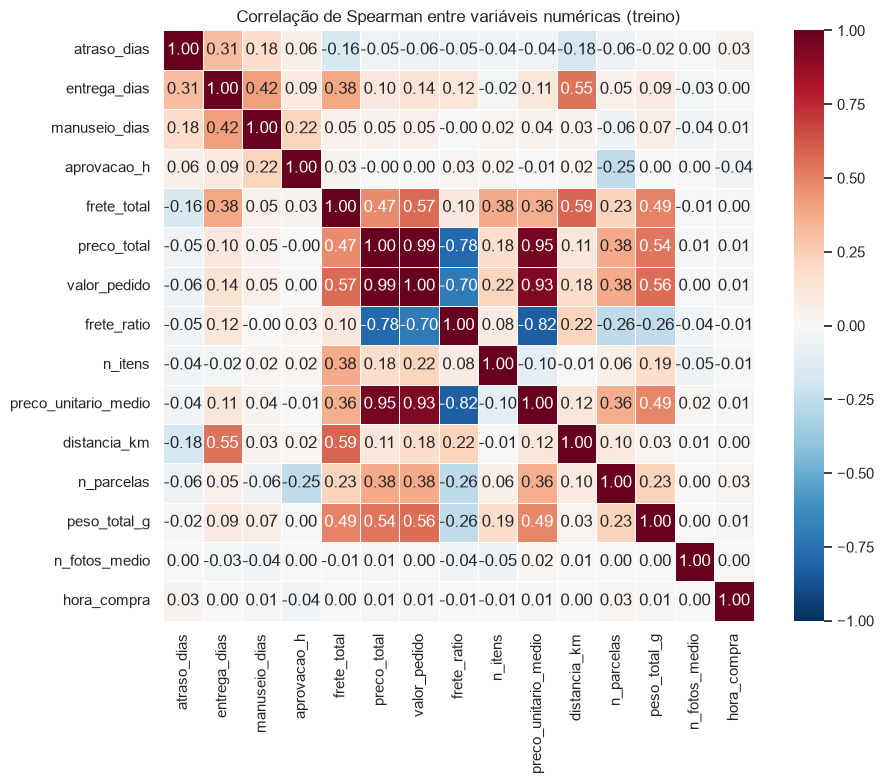

spearman
preco_total  valor_pedido          0.989640
             preco_unitario_medio  0.954079
valor_pedido preco_unitario_medio  0.930203
frete_ratio  preco_unitario_medio -0.821785
preco_total  frete_ratio          -0.783983
valor_pedido frete_ratio          -0.704933

In [33]:
identidade = (X_train["valor_pedido"] - X_train["preco_total"] - X_train["frete_total"]).abs().max()
print("Maior |valor_pedido - (preco_total + frete_total)| no treino:", identidade)

corr = X_train[numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, ax=ax)
ax.set_title("Correlação de Spearman entre variáveis numéricas (treino)")
plt.tight_layout()
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pares[pares.abs() >= 0.7].sort_values(key=abs, ascending=False).to_frame("spearman")


- Removidos: `valor_pedido` (soma exata de `preco_total` e `frete_total`) e
  `preco_unitario_medio` (`preco_total / n_itens`). Critério: ρ de Spearman ≥ 0,90 ou identidade exata.
- Mantido: `frete_ratio` (ρ máx. 0,82; expressa o peso do frete no pedido).
- Nenhuma variável é constante ou quase constante.

In [34]:
remover = ["valor_pedido", "preco_unitario_medio"]

numericas = [c for c in numericas if c not in remover]
X = X.drop(columns=remover)
X_train = X_train.drop(columns=remover)
X_test = X_test.drop(columns=remover)

print("Numéricas restantes:", len(numericas), "| categóricas:", len(categoricas))
print("Formato treino:", X_train.shape, "| teste:", X_test.shape)

Numéricas restantes: 13 | categóricas: 6
Formato treino: (76658, 19) | teste: (19166, 19)


In [35]:
assimetria = X_train[numericas].skew()
candidatas = assimetria[assimetria >= 3].index
log_cols = [c for c in candidatas if X_train[c].min() >= 0]

print("Recebem log1p:")
print(assimetria[log_cols].round(1).sort_values(ascending=False).to_string())
print("\nSem log:", [c for c in numericas if c not in log_cols])

Recebem log1p:
frete_total      13.5
preco_total      10.1
n_itens           7.2
peso_total_g      6.8
manuseio_dias     4.7
aprovacao_h       4.2
entrega_dias      3.8

Sem log: ['atraso_dias', 'frete_ratio', 'distancia_km', 'n_parcelas', 'n_fotos_medio', 'hora_compra']


In [36]:
from sklearn.preprocessing import OneHotEncoder

print("Níveis por variável categórica (treino):")
print(X_train[categoricas].nunique().to_string())
print("\nColunas geradas pelo one-hot:")
print("  sem agrupar raros      :", int(X_train[categoricas].nunique().sum()))
for nome, mf in {"min_frequency=30": 30, "0,5% do treino": 0.005, "1% do treino": 0.01}.items():
    ohe = OneHotEncoder(handle_unknown="ignore", min_frequency=mf, sparse_output=False)
    ohe.fit(X_train[categoricas].fillna("ausente"))
    print(f"  {nome:22s}:", len(ohe.get_feature_names_out()))

Níveis por variável categórica (treino):
categoria_principal    74
uf_cliente             27
uf_vendedor            22
pagamento_tipo          4
mes_compra             12
dia_semana_compra       7

Colunas geradas pelo one-hot:
  sem agrupar raros      : 146


  min_frequency=30      : 129


  0,5% do treino        : 80


  1% do treino          : 67



Uma receita única (`ColumnTransformer`), ajustada **somente no treino** e aplicada ao teste:

| Grupo | Passos | Problema que justifica |
|---|---|---|
| 7 numéricas assimétricas | `log1p` → mediana → padronização | Caudas longas (assimetria ≥ 3); ausências raras |
| 6 numéricas restantes | mediana → padronização | Escalas diferentes; ausências raras |
| 6 categóricas | moda → one-hot (`min_frequency=0.005`) | Sem ordem natural; níveis raros agrupados |

Não há variável ordinal: mês e dia da semana são nominais (cíclicos), e as UFs e categorias não têm ordem.

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder

sem_log = [c for c in numericas if c not in log_cols]

num_log = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])
num_linear = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])
cat = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.005, sparse_output=False)),
])

pre = ColumnTransformer(
    [("num_log", num_log, log_cols),
     ("num", num_linear, sem_log),
     ("cat", cat, categoricas)],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

Xtr = pre.fit_transform(X_train)      # aprende E aplica, so no treino
Xte = pre.transform(X_test)           # só aplica, com o que aprendeu no treino

print("Treino:", Xtr.shape, "| Teste:", Xte.shape)
print("Ausentes restantes  treino:", int(Xtr.isna().sum().sum()), "| teste:", int(Xte.isna().sum().sum()))

Treino: (76658, 92) | Teste: (19166, 92)
Ausentes restantes  treino: 0 | teste: 0


In [38]:
colunas_num = log_cols + sem_log

verificacao = pd.DataFrame({
    "média treino": Xtr[colunas_num].mean(),
    "desvio treino": Xtr[colunas_num].std(),
    "média teste": Xte[colunas_num].mean(),
    "desvio teste": Xte[colunas_num].std(),
}).round(3)
display(verificacao)

print("Assimetria antes -> depois do log1p:")
print(pd.DataFrame({"antes": X_train[log_cols].skew(), "depois": Xtr[log_cols].skew()}).round(1).to_string())

,média treino,desvio treino,média teste,desvio teste
entrega_dias,-0.0,1.0,0.012,0.991
manuseio_dias,0.0,1.0,0.003,1.004
aprovacao_h,0.0,1.0,0.009,1.005
frete_total,-0.0,1.0,0.004,0.989
preco_total,-0.0,1.0,-0.001,0.997
n_itens,0.0,1.0,-0.001,0.986
peso_total_g,0.0,1.0,0.005,0.993
atraso_dias,-0.0,1.0,0.002,0.988
frete_ratio,0.0,1.0,0.003,1.002
distancia_km,0.0,1.0,0.011,1.000


Assimetria antes -> depois do log1p:
               antes  depois
entrega_dias     3.8     0.0
manuseio_dias    4.7     0.6
aprovacao_h      4.2     1.0
frete_total     13.5     0.5
preco_total     10.1     0.3
n_itens          7.2     4.0
peso_total_g     6.8     0.5


In [39]:
print("pagamento_tipo ausente no treino:", int(X_train["pagamento_tipo"].isna().sum()))
print("Colunas 'infrequent' no pipeline real:",
      [n for n in pre.get_feature_names_out() if "infrequent" in n])

pagamento_tipo ausente no treino: 1
Colunas 'infrequent' no pipeline real: ['categoria_principal_infrequent_sklearn', 'uf_cliente_infrequent_sklearn', 'uf_vendedor_infrequent_sklearn']



Alvo: `insatisfeito`. Métodos: **Filtro** (informação mútua e qui-quadrado), **Embutido**
(regressão logística com penalização L1) e **Wrapper** (RFE). Os modelos são usados só como
instrumento de ranqueamento: não avaliamos desempenho preditivo.

In [40]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

Xmi = X_train.copy()
Xmi[numericas] = SimpleImputer(strategy="median").fit_transform(Xmi[numericas])
Xmi[categoricas] = OrdinalEncoder().fit_transform(Xmi[categoricas].fillna("ausente"))

discretas = [False] * len(numericas) + [True] * len(categoricas)

def calcular_mi(alvo):
    return pd.Series(
        mutual_info_classif(Xmi[numericas + categoricas], alvo,
                            discrete_features=discretas, random_state=RANDOM_STATE),
        index=numericas + categoricas)

mi = calcular_mi(y_train)

rng = np.random.default_rng(RANDOM_STATE)
mi_ruido = pd.concat([calcular_mi(pd.Series(rng.permutation(y_train.values), index=y_train.index))
                      for _ in range(3)], axis=1)
ruido_proprio = mi_ruido.max(axis=1)

tabela_mi = pd.DataFrame({
    "mi": mi,
    "ruido_proprio": ruido_proprio,
    "acima_do_ruido": mi > ruido_proprio,
}).sort_values("mi", ascending=False).round(4)
tabela_mi

,mi,ruido_proprio,acima_do_ruido
atraso_dias,0.0584,0.0025,True
entrega_dias,0.0478,0.0009,True
n_itens,0.0139,0.0077,True
frete_total,0.0099,0.0011,True
manuseio_dias,0.0097,0.0011,True
frete_ratio,0.0092,0.0013,True
preco_total,0.0062,0.0002,True
peso_total_g,0.0051,0.0017,True
mes_compra,0.0047,0.0001,True
uf_cliente,0.0035,0.0002,True


In [41]:
p = y_train.mean()
entropia_alvo = -(p * np.log(p) + (1 - p) * np.log(1 - p))   # incerteza total sobre o alvo, em nats

tabela_mi["% da incerteza do alvo"] = (tabela_mi["mi"] / entropia_alvo * 100).round(1)
print(f"Entropia do alvo: {entropia_alvo:.3f} nats")
tabela_mi

Entropia do alvo: 0.383 nats


,mi,ruido_proprio,acima_do_ruido,% da incerteza do alvo
atraso_dias,0.0584,0.0025,True,15.3
entrega_dias,0.0478,0.0009,True,12.5
n_itens,0.0139,0.0077,True,3.6
frete_total,0.0099,0.0011,True,2.6
manuseio_dias,0.0097,0.0011,True,2.5
frete_ratio,0.0092,0.0013,True,2.4
preco_total,0.0062,0.0002,True,1.6
peso_total_g,0.0051,0.0017,True,1.3
mes_compra,0.0047,0.0001,True,1.2
uf_cliente,0.0035,0.0002,True,0.9


In [42]:
from scipy.stats import chi2_contingency

linhas = []
for c in categoricas:
    tab = pd.crosstab(X_train[c].fillna("ausente"), y_train)
    chi2, p, _, _ = chi2_contingency(tab)
    v_cramer = np.sqrt(chi2 / (tab.to_numpy().sum() * (min(tab.shape) - 1)))
    linhas.append({"variavel": c, "niveis": tab.shape[0], "chi2": round(chi2, 1),
                   "p": p, "V_de_Cramer": round(v_cramer, 4)})

pd.DataFrame(linhas).sort_values("V_de_Cramer", ascending=False)

,variavel,niveis,chi2,p,V_de_Cramer
4,mes_compra,12,739.2,2.156516e-151,0.0982
1,uf_cliente,27,567.0,4.326662e-103,0.0860
0,categoria_principal,74,418.7,5.656446e-50,0.0739
2,uf_vendedor,22,93.5,3.995455e-11,0.0349
5,dia_semana_compra,7,15.7,1.527725e-02,0.0143
3,pagamento_tipo,5,13.7,8.159789e-03,0.0134


In [43]:
Xsel = (Xtr - Xtr.mean()) / Xtr.std()

print("Colunas com desvio zero:", int((Xtr.std() == 0).sum()))
print("Média e desvio máximos após padronizar:", round(Xsel.mean().abs().max(), 6), round(Xsel.std().max(), 3))

Colunas com desvio zero: 0
Média e desvio máximos após padronizar: 0.0 1.0


In [44]:
from sklearn.linear_model import LogisticRegression

nomes = list(Xtr.columns)

def variavel_original(coluna):
    for v in categoricas:                      # "uf_cliente_SP" -> "uf_cliente"
        if coluna.startswith(v + "_"):
            return v
    return coluna

origem = pd.Series([variavel_original(c) for c in nomes], index=nomes)

caminho = {}
for C in [0.0005, 0.001, 0.003, 0.01, 0.03]:
    lr = LogisticRegression(l1_ratio=1, solver="liblinear", C=C,
                            class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
    lr.fit(Xsel, y_train)
    coef = pd.Series(np.abs(lr.coef_.ravel()), index=nomes)
    caminho[f"C={C}"] = (coef.groupby(origem).sum() > 0).astype(int)   # sobrevive se algum coeficiente != 0

caminho = pd.DataFrame(caminho)
caminho["n_modelos"] = caminho.sum(axis=1)
caminho.sort_values("n_modelos", ascending=False)

,C=0.0005,C=0.001,C=0.003,C=0.01,C=0.03,n_modelos
atraso_dias,1,1,1,1,1,5
n_itens,1,1,1,1,1,5
entrega_dias,1,1,1,1,1,5
uf_cliente,0,1,1,1,1,4
categoria_principal,0,1,1,1,1,4
n_parcelas,0,1,1,1,1,4
manuseio_dias,0,1,1,1,1,4
pagamento_tipo,0,1,1,1,1,4
uf_vendedor,0,0,1,1,1,3
mes_compra,0,0,1,1,1,3


In [45]:
import time
from sklearn.feature_selection import RFE

inicio = time.time()
rfe = RFE(
    LogisticRegression(C=0.1, class_weight="balanced", max_iter=1000),
    n_features_to_select=1,     # elimina até sobrar 1: o ranking completo
    step=3,                     # remove 3 colunas por rodada
)
rfe.fit(Xsel, y_train)
print(f"RFE levou {time.time() - inicio:.0f} s")

rank_coluna = pd.Series(rfe.ranking_, index=Xtr.columns)         # 1 = última a ser eliminada
rank_variavel = rank_coluna.groupby(origem).min().sort_values()  # melhor coluna de cada variável

print("Ranking das variáveis originais (1 = melhor):")
rank_variavel.to_frame("rank_rfe")

RFE levou 9 s
Ranking das variáveis originais (1 = melhor):


,rank_rfe
entrega_dias,1
n_itens,2
pagamento_tipo,3
atraso_dias,3
uf_cliente,3
mes_compra,4
manuseio_dias,4
categoria_principal,5
n_parcelas,7
distancia_km,8


In [46]:
conv = pd.DataFrame({
    "MI_%": tabela_mi["% da incerteza do alvo"],
    "L1_de_5": caminho["n_modelos"],
    "RFE_rank": rank_variavel,
})

conv["filtro"] = (tabela_mi["acima_do_ruido"] & (conv["MI_%"] >= 0.5)).astype(int)
conv["embutido"] = (conv["L1_de_5"] >= 3).astype(int)
conv["wrapper"] = (conv["RFE_rank"] <= 8).astype(int)
conv["votos"] = conv[["filtro", "embutido", "wrapper"]].sum(axis=1)

conv.sort_values(["votos", "MI_%"], ascending=False)

,MI_%,L1_de_5,RFE_rank,filtro,embutido,wrapper,votos
atraso_dias,15.3,5,3,1,1,1,3
entrega_dias,12.5,5,1,1,1,1,3
n_itens,3.6,5,2,1,1,1,3
manuseio_dias,2.5,4,4,1,1,1,3
mes_compra,1.2,3,4,1,1,1,3
n_parcelas,0.9,4,7,1,1,1,3
uf_cliente,0.9,4,3,1,1,1,3
categoria_principal,0.7,4,5,1,1,1,3
distancia_km,0.4,3,8,0,1,1,2
uf_vendedor,0.2,3,8,0,1,1,2


In [47]:
d = X_train.assign(insatisfeito=y_train)

print("Taxa de insatisfação por tipo de pagamento (todos):")
print(d.groupby("pagamento_tipo")["insatisfeito"].agg(["mean", "size"]).round(3).to_string())

print("\nSó pedidos com 1 parcela:")
print(d[d["n_parcelas"] == 1].groupby("pagamento_tipo")["insatisfeito"].agg(["mean", "size"]).round(3).to_string())

Taxa de insatisfação por tipo de pagamento (todos):
                 mean   size
pagamento_tipo              
boleto          0.124  15257
credit_card     0.129  57835
debit_card      0.111   1170
voucher         0.133   2395

Só pedidos com 1 parcela:
                 mean   size
pagamento_tipo              
boleto          0.124  15257
credit_card     0.113  18593
debit_card      0.111   1170
voucher         0.134   2232


In [48]:
mantidas_num = ["atraso_dias", "entrega_dias", "n_itens", "manuseio_dias", "n_parcelas", "distancia_km"]
um_voto = ["frete_total", "frete_ratio", "preco_total", "peso_total_g"]

corr = X_train[um_voto + mantidas_num].corr(method="spearman")

print("Entre as 4 candidatas a sair:")
display(corr.loc[um_voto, um_voto].round(2))
print("Candidatas a sair x variáveis mantidas:")
display(corr.loc[um_voto, mantidas_num].round(2))

Entre as 4 candidatas a sair:


,frete_total,frete_ratio,preco_total,peso_total_g
frete_total,1.00,0.10,0.47,0.49
frete_ratio,0.10,1.00,-0.78,-0.26
preco_total,0.47,-0.78,1.00,0.54
peso_total_g,0.49,-0.26,0.54,1.00


Candidatas a sair x variáveis mantidas:


,atraso_dias,entrega_dias,n_itens,manuseio_dias,n_parcelas,distancia_km
frete_total,-0.16,0.38,0.38,0.05,0.23,0.59
frete_ratio,-0.05,0.12,0.08,-0.00,-0.26,0.22
preco_total,-0.05,0.10,0.18,0.05,0.38,0.11
peso_total_g,-0.02,0.09,0.19,0.07,0.23,0.03


In [49]:
selecionadas = conv.index[conv["votos"] >= 2].tolist()
descartadas = conv.index[conv["votos"] < 2].tolist()

colunas_sel = [c for c in Xtr.columns if variavel_original(c) in selecionadas]
Xtr_sel, Xte_sel = Xtr[colunas_sel], Xte[colunas_sel]

n_num = sum(c in numericas for c in colunas_sel)
print(f"Selecionadas ({len(selecionadas)}): {selecionadas}")
print(f"Descartadas  ({len(descartadas)}): {descartadas}")
print(f"\nColunas: {Xtr.shape[1]} -> {Xtr_sel.shape[1]}  ({n_num} numéricas + {Xtr_sel.shape[1] - n_num} one-hot)")

Selecionadas (11): ['atraso_dias', 'categoria_principal', 'distancia_km', 'entrega_dias', 'manuseio_dias', 'mes_compra', 'n_itens', 'n_parcelas', 'pagamento_tipo', 'uf_cliente', 'uf_vendedor']
Descartadas  (8): ['aprovacao_h', 'dia_semana_compra', 'frete_ratio', 'frete_total', 'hora_compra', 'n_fotos_medio', 'peso_total_g', 'preco_total']

Colunas: 92 -> 78  (6 numéricas + 72 one-hot)



O PCA é aplicado **somente às 13 variáveis numéricas** já limpas, transformadas e padronizadas:
combinações lineares só fazem sentido para variáveis contínuas, e não para colunas 0/1 do one-hot.
O ajuste é feito **no treino**; o teste só é projetado. O número de componentes é decidido por
critérios combinados (cotovelo, Kaiser, análise paralela), e não apenas por um percentual de variância.

In [50]:
from sklearn.decomposition import PCA

num_cols = log_cols + sem_log                      # as 13 numéricas, já transformadas
Znum_tr, Znum_te = Xtr[num_cols], Xte[num_cols]

print("Posto da matriz:", np.linalg.matrix_rank(Znum_tr.to_numpy()), "de", len(num_cols), "colunas")

pca = PCA().fit(Znum_tr)                           # ajusta SÓ no treino
autovalores = pca.explained_variance_
variancia = pca.explained_variance_ratio_

tabela_pca = pd.DataFrame({
    "autovalor": autovalores,
    "variancia_%": variancia * 100,
    "acumulada_%": np.cumsum(variancia) * 100,
}, index=[f"CP{i+1}" for i in range(len(autovalores))]).round(2)
tabela_pca

Posto da matriz: 13 de 13 colunas


,autovalor,variancia_%,acumulada_%
CP1,2.70,20.73,20.73
CP2,2.02,15.50,36.24
CP3,1.52,11.71,47.94
CP4,1.20,9.23,57.17
CP5,1.05,8.06,65.24
CP6,0.99,7.63,72.86
CP7,0.94,7.25,80.12
CP8,0.74,5.67,85.79
CP9,0.67,5.16,90.95
CP10,0.62,4.74,95.68


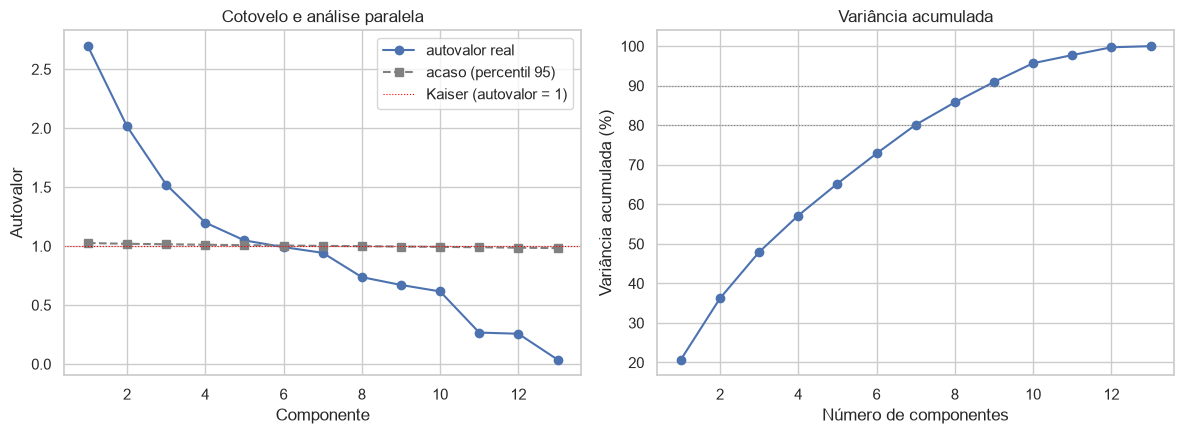

Componentes acima do acaso (análise paralela): 5


In [51]:
rng = np.random.default_rng(RANDOM_STATE)
Z = Znum_tr.to_numpy()

simulados = np.empty((100, Z.shape[1]))
for r in range(100):
    Z_emb = np.column_stack([rng.permutation(Z[:, j]) for j in range(Z.shape[1])])
    simulados[r] = PCA().fit(Z_emb).explained_variance_

limite_95 = np.percentile(simulados, 95, axis=0)
acima = autovalores > limite_95
n_paralela = int(np.argmin(acima)) if not acima.all() else len(acima)   # quantas, em sequência, superam o acaso

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
k = np.arange(1, len(autovalores) + 1)

eixos[0].plot(k, autovalores, "o-", label="autovalor real")
eixos[0].plot(k, limite_95, "s--", color="gray", label="acaso (percentil 95)")
eixos[0].axhline(1, color="red", lw=0.8, ls=":", label="Kaiser (autovalor = 1)")
eixos[0].set(xlabel="Componente", ylabel="Autovalor", title="Cotovelo e análise paralela")
eixos[0].legend()

eixos[1].plot(k, np.cumsum(variancia) * 100, "o-")
for alvo in (80, 90):
    eixos[1].axhline(alvo, color="gray", lw=0.8, ls=":")
eixos[1].set(xlabel="Número de componentes", ylabel="Variância acumulada (%)", title="Variância acumulada")

plt.tight_layout()
plt.show()
print("Componentes acima do acaso (análise paralela):", n_paralela)

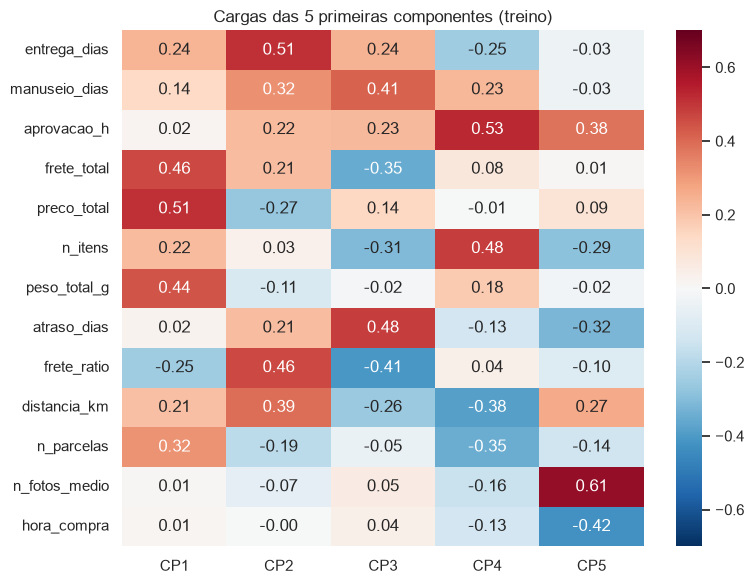

Maiores cargas (em módulo) da CP13, a de menor variância:
preco_total    0.68
frete_ratio    0.60
frete_total    0.42
n_parcelas     0.03


In [52]:
cargas = pd.DataFrame(pca.components_.T, index=num_cols,
                      columns=[f"CP{i+1}" for i in range(len(num_cols))])

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cargas[["CP1", "CP2", "CP3", "CP4", "CP5"]], annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-0.7, vmax=0.7, ax=ax)
ax.set_title("Cargas das 5 primeiras componentes (treino)")
plt.tight_layout()
plt.show()

print("Maiores cargas (em módulo) da CP13, a de menor variância:")
print(cargas["CP13"].abs().sort_values(ascending=False).head(4).round(2).to_string())

In [53]:
def r2_por_variavel(original, reconstruido):
    sq_res = ((original - reconstruido) ** 2).sum(axis=0)
    sq_tot = ((original - original.mean(axis=0)) ** 2).sum(axis=0)
    return 1 - sq_res / sq_tot

Zte = Znum_te.to_numpy()
resultados = {}
for k in (5, 9):
    pca_k = PCA(n_components=k).fit(Znum_tr)                      # ajusta no treino
    reconstruido = pca_k.inverse_transform(pca_k.transform(Zte))  # comprime e reconstrói o TESTE
    resultados[f"PCA k={k}"] = pd.Series(r2_por_variavel(Zte, reconstruido), index=num_cols)

recon = pd.DataFrame(resultados).round(2)
recon.loc["média"] = recon.mean().round(2)
recon

C:\Users\yagom\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\yagom\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


,PCA k=5,PCA k=9
entrega_dias,0.83,0.84
manuseio_dias,0.60,0.92
aprovacao_h,0.67,0.86
frete_total,0.86,0.88
preco_total,0.89,0.94
n_itens,0.65,0.91
peso_total_g,0.58,0.88
atraso_dias,0.58,0.93
frete_ratio,0.87,0.93
distancia_km,0.78,0.89


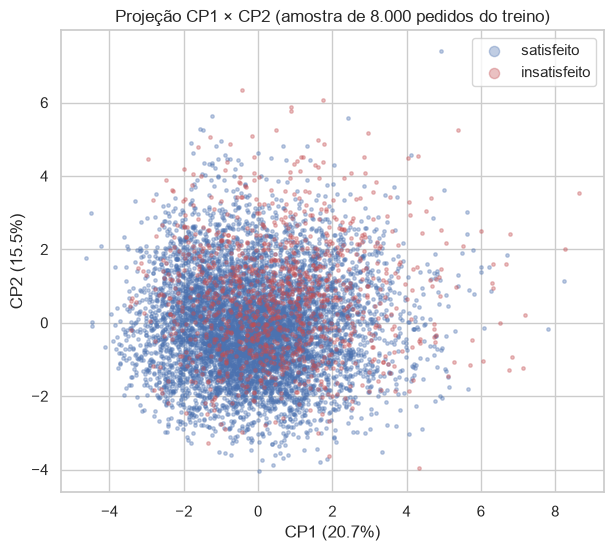

,mi,% da incerteza do alvo
CP1,0.0088,2.3
CP2,0.0163,4.3
CP3,0.0216,5.6
CP4,0.0075,2.0
CP5,0.0131,3.4


In [54]:
proj_tr = pca.transform(Znum_tr)[:, :5]
amostra = np.random.default_rng(RANDOM_STATE).choice(len(proj_tr), 8000, replace=False)
alvo_amostra = y_train.to_numpy()[amostra]

fig, ax = plt.subplots(figsize=(7, 6))
for classe, cor, rotulo in [(0, "#4c72b0", "satisfeito"), (1, "#c44e52", "insatisfeito")]:
    m = alvo_amostra == classe
    ax.scatter(proj_tr[amostra][m, 0], proj_tr[amostra][m, 1], s=6, alpha=0.35, c=cor, label=rotulo)
ax.set(xlabel=f"CP1 ({variancia[0]*100:.1f}%)", ylabel=f"CP2 ({variancia[1]*100:.1f}%)",
       title="Projeção CP1 × CP2 (amostra de 8.000 pedidos do treino)")
ax.legend(markerscale=3)
plt.show()

mi_cp = mutual_info_classif(proj_tr, y_train, random_state=RANDOM_STATE)
pd.DataFrame({"mi": mi_cp.round(4), "% da incerteza do alvo": (mi_cp / entropia_alvo * 100).round(1)},
             index=[f"CP{i+1}" for i in range(5)])

In [55]:
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

mantidas = [c for c in num_cols if c in selecionadas]
descartadas_num = [c for c in num_cols if c not in selecionadas]

r2_sel = pd.Series(1.0, index=num_cols)
for c in descartadas_num:
    reg = LinearRegression().fit(Znum_tr[mantidas], Znum_tr[c])
    r2_sel[c] = r2_score(Znum_te[c], reg.predict(Znum_te[mantidas]))

pca6 = PCA(n_components=len(mantidas)).fit(Znum_tr)
rec6 = pca6.inverse_transform(pca6.transform(Znum_te))
r2_pca6 = pd.Series(r2_por_variavel(Znum_te.to_numpy(), rec6), index=num_cols)

comp = pd.DataFrame({"Seleção (6 variáveis)": r2_sel, "PCA (6 componentes)": r2_pca6})
comp["relevância (% incerteza do alvo)"] = tabela_mi["% da incerteza do alvo"].reindex(comp.index)

for col in ["Seleção (6 variáveis)", "PCA (6 componentes)"]:
    simples = comp[col].mean()
    ponderado = np.average(comp[col], weights=comp["relevância (% incerteza do alvo)"])
    print(f"{col:24s} R² médio: {simples:.2f} | ponderado pela relevância: {ponderado:.2f}")

comp.round(2)

Seleção (6 variáveis)    R² médio: 0.54 | ponderado pela relevância: 0.85
PCA (6 componentes)      R² médio: 0.73 | ponderado pela relevância: 0.71


,Seleção (6 variáveis),PCA (6 componentes),relevância (% incerteza do alvo)
entrega_dias,1.00,0.84,12.5
manuseio_dias,1.00,0.60,2.5
aprovacao_h,0.12,0.69,0.1
frete_total,0.44,0.87,2.6
preco_total,0.20,0.89,1.6
n_itens,1.00,0.65,3.6
peso_total_g,0.11,0.59,1.3
atraso_dias,1.00,0.59,15.3
frete_ratio,0.13,0.87,2.4
distancia_km,1.00,0.78,0.4


In [56]:
w = tabela_mi["% da incerteza do alvo"].reindex(num_cols)

def resumo_pca(k):
    p = PCA(n_components=k).fit(Znum_tr)
    rec = p.inverse_transform(p.transform(Znum_te))
    r2 = pd.Series(r2_por_variavel(Znum_te.to_numpy(), rec), index=num_cols)
    return r2.mean(), np.average(r2, weights=w)

n_ohe_total = Xtr.shape[1] - len(num_cols)        # colunas one-hot (não entram no PCA)

linhas = {
    "A. Pré-processada completa":      (Xtr.shape[1], 1.0, 1.0),
    "B. Seleção de atributos":         (Xtr_sel.shape[1], r2_sel.mean(), np.average(r2_sel, weights=w)),
    "C1. PCA (k=5) + one-hot":         (5 + n_ohe_total, *resumo_pca(5)),
    "C2. PCA (k=9) + one-hot":         (9 + n_ohe_total, *resumo_pca(9)),
}
final = pd.DataFrame(linhas, index=["colunas", "R² médio (numéricas)", "R² ponderado (numéricas)"]).T
final["redução de colunas (%)"] = ((1 - final["colunas"] / Xtr.shape[1]) * 100).round(0)
final.round(2)

,colunas,R² médio (numéricas),R² ponderado (numéricas),redução de colunas (%)
A. Pré-processada completa,92.0,1.00,1.00,0.0
B. Seleção de atributos,78.0,0.54,0.85,15.0
C1. PCA (k=5) + one-hot,84.0,0.65,0.70,9.0
C2. PCA (k=9) + one-hot,88.0,0.91,0.90,4.0


In [57]:
OUT = ROOT / "outputs"

def salvar(X_df, y, nome):
    df = X_df.astype("float32").assign(insatisfeito=y.to_numpy()).reset_index(names="order_id")
    df.to_parquet(OUT / nome, index=False)
    print(f"{nome:36s} {df.shape[0]:>7,} x {df.shape[1]:>3} colunas")

salvar(Xtr_sel, y_train, "treino_selecionada.parquet")
salvar(Xte_sel, y_test,  "teste_selecionada.parquet")
salvar(Xtr, y_train, "treino_completa.parquet")
salvar(Xte, y_test,  "teste_completa.parquet")

pca5 = PCA(n_components=5).fit(Znum_tr)
comp_tr = pd.DataFrame(pca5.transform(Znum_tr), index=Znum_tr.index, columns=[f"CP{i+1}" for i in range(5)])
comp_te = pd.DataFrame(pca5.transform(Znum_te), index=Znum_te.index, columns=[f"CP{i+1}" for i in range(5)])
salvar(comp_tr, y_train, "treino_pca5.parquet")
salvar(comp_te, y_test,  "teste_pca5.parquet")

treino_selecionada.parquet            76,658 x  80 colunas
teste_selecionada.parquet             19,166 x  80 colunas


treino_completa.parquet               76,658 x  94 colunas
teste_completa.parquet                19,166 x  94 colunas


treino_pca5.parquet                   76,658 x   7 colunas
teste_pca5.parquet                    19,166 x   7 colunas




- **Alvo definido por nós.** `insatisfeito = review_score ≤ 2` é uma convenção. Nenhuma variável do dataset é um alvo "oficial".
- **Viés de seleção.** O recorte exige pedido entregue e avaliado: 646 pedidos (0,67%) entregues, mas sem avaliação, ficaram de fora.
- **Distância com precisão de CEP.** É calculada entre centros de prefixos de CEP (mediana das coordenadas), não entre endereços; usa o vendedor do item mais caro. 22 pedidos têm distância 0 (mesmo prefixo) e 476 (0,5%) ficaram sem coordenada, imputados pela mediana do treino.
- **Valores incertos mantidos.** Postagem anterior à aprovação do pagamento (1.343 pedidos) e aprovações de até 31 dias, inclusive em cartão (32 de 72.331 acima de 7 dias), não puderam ser classificadas como erro ou prática normal sem conhecimento do processo da empresa.
- **`mes_compra` (1–12) mistura anos.** Foi a categórica com maior V de Cramér (0,098), mas esse efeito pode vir de eventos pontuais (ex.: picos de insatisfação em meses específicos de 2018) e não de sazonalidade. É uma hipótese, não verificada aqui.
- **Assimetria residual.** `n_itens` (90% dos pedidos com 1 item) manteve assimetria 4,0 após `log1p`. `hora_compra` é cíclica (23h é vizinha de 0h) e foi tratada como linear.
- **Observações não totalmente independentes.** Clientes recorrentes foram mantidos no mesmo conjunto (treino ou teste), mas pedidos do mesmo cliente continuam correlacionados entre si.


**Seleção de atributos**
- Os cortes usados são julgamentos declarados antes de ver os resultados: MI ≥ 0,5% da incerteza do alvo e acima do ruído próprio; L1 em pelo menos 3 de 5 valores de `C`; RFE entre as 8 melhores posições.
- Não há análise de estabilidade: uma única partição treino/teste, uma semente, e o piso de ruído da MI vem de apenas 3 embaralhamentos.
- L1 e RFE foram agregados por variável original ("qualquer coluna one-hot com coeficiente ≠ 0"), o que favorece variáveis com muitos níveis.
- Filtro mede relação marginal; L1 e RFE (regressão logística, portanto lineares) medem efeito condicional. A divergência entre eles (ex.: `pagamento_tipo`, `frete_total`) não foi totalmente explicada.
- O wrapper usou `step=3` (3 colunas removidas por rodada) por custo.
- **As 7 variáveis numéricas descartadas não eram redundantes:** só 0 a 44% da variação de cada uma é recuperável a partir das mantidas (`aprovacao_h` 0,12; `frete_ratio` 0,13; `peso_total_g` 0,11; `preco_total` 0,20; `frete_total` 0,44; `n_fotos_medio` e `hora_compra` 0,00). Foram descartadas por **falta de contribuição adicional para o alvo**, o que implica perda real de informação.

**PCA**
- Aplicado apenas às 13 variáveis numéricas. As 79 colunas one-hot (86% da dimensionalidade) ficam fora, porque PCA não é adequado a variáveis binárias.
- É linear e **não supervisionado**: ordena por variância, não por relevância. A CP1 é formada por variáveis que a seleção descartou, `atraso_dias` (a mais informativa) fica diluída (R² de reconstrução 0,58 com k=5) e a CP5 é dominada por `n_fotos_medio` e `hora_compra`.
- O número de componentes (k=5, por Kaiser e análise paralela) preserva só 65% da variância; 9 componentes preservam 91%. A escolha entre eles depende do objetivo.

**Comparação entre estratégias**
- "Informação preservada" foi medida por reconstrução (R²) e informação mútua com o alvo, **sem treinar modelos preditivos** (fora do escopo). Não sabemos como cada representação se comportaria numa tarefa de modelagem.
- O R² ponderado pela relevância usa a MI com o alvo como peso, e a seleção foi feita a partir do alvo: a vantagem da seleção nessa métrica é, em parte, circular.
- **Nenhuma estratégia reduz muito a dimensão total** (seleção −15%; PCA −9% com k=5 e −4% com k=9), porque o one-hot domina (`categoria_principal` tem 74 níveis).


| Decisão atual | O que poderia mudar | Efeito possível |
|---|---|---|
| Avaliação mais recente quando há duas | Regra de negócio definir a primeira ou a média | Altera a classe de apenas 96 pedidos (0,097%) |
| Alvo = nota ≤ 2 | Usar nota ≤ 3, ou a nota em escala 1–5 | Mudaria o ranking de variáveis na seleção |
| `manuseio_dias` negativo → ausente (164 pedidos) | Logística confirmar que são diferenças de fuso/registro | Poderiam ser truncados em 0 em vez de ausentes |
| Aprovação demorada e postagem antes da aprovação mantidas | Confirmar que são erro (ou prática antifraude) | Remover ou sinalizar esses pedidos |
| `frete_total`, `preco_total`, `peso_total_g`, `frete_ratio` descartados | A empresa tratar política de frete ou valor como alavanca de ação | Mantê-las, mesmo sem apoio dos métodos multivariados |
| `categoria_principal` com 74 níveis (`min_frequency` 0,5%) | Existir uma hierarquia de categorias de produto | Agrupar em macrocategorias reduziria dezenas de colunas: **a redução de dimensionalidade mais efetiva** |
| UFs como categorias independentes | Agrupar por região | Menos colunas, interpretação mais robusta |
| `hora_compra` linear | Codificação cíclica (seno/cosseno) | Poderia ganhar relevância |


- Refazer a **seleção dentro de uma validação cruzada agrupada por cliente**, para medir a estabilidade do subconjunto escolhido.
- Tratar o **desbalanceamento** (12,8% de insatisfeitos) com métricas apropriadas.
- Comparar, no problema real, as três bases salvas (`selecionada`, `completa`, `pca5`). A recomendação deste trabalho é a base `selecionada`, mas ela não foi testada em modelagem.
- Investigar a causa da divergência entre o filtro e os métodos multivariados em `pagamento_tipo`, `frete_total` e `mes_compra`.


**Como preparar e reduzir a base preservando a informação relevante?**

1. **Pré-processamento:** o recorte (95.824 pedidos entregues e avaliados), a invalidação de 166 valores impossíveis, o `log1p` em 7 variáveis assimétricas e o one-hot com agrupamento de níveis raros (79 colunas) resolveram problemas **medidos** na base. Tudo o que aprende dos dados foi ajustado só no treino, com divisão estratificada e agrupada por cliente.
2. **Redundância:** `valor_pedido` (soma exata) e `preco_unitario_medio` foram removidas; `frete_ratio` mostrou-se quase redundante com `preco_total` e `frete_total` (CP13).
3. **Seleção (Filtro, Embutido e Wrapper):** 8 variáveis foram sustentadas pelos três métodos; `atraso_dias`, `entrega_dias` e `n_itens` lideram em todos. 11 variáveis (≥ 2 votos) formam a base final de **78 colunas**.
4. **PCA:** 5 componentes (Kaiser e análise paralela concordam) preservam 65% da variância; a projeção CP1 × CP2 não mostra separação visual entre satisfeitos e insatisfeitos.
5. **Comparação:** a seleção preserva melhor as variáveis relevantes e o significado original; o PCA preserva melhor a variância total, mas dilui as variáveis mais informativas e perde interpretabilidade. Como as colunas one-hot dominam a dimensionalidade, **nenhuma das estratégias reduz a base de forma expressiva** (no máximo −15%).

**Representação recomendada:** a base com seleção de atributos (`outputs/treino_selecionada.parquet` e `teste_selecionada.parquet`).